# Figure 4B — EPM spatial activity

The panel follows the native-coordinate construction used by the original
notebook.

**Inputs:**

- `data/source_data/figure_04/fig_4b_nc102_spatial_activity.csv`

**Output:** `results/figures/Fig_4B.png`

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utilities import ensure_directory, native_spatial_activity_image, project_path, save_figure

OUTPUT_DIR = ensure_directory(project_path("results", "figures", root=REPO_ROOT))

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
MOUSE_ID = "NC102_RTT"
spatial_path = project_path(
    "data", "source_data", "figure_04",
    "fig_4b_nc102_spatial_activity.csv", root=REPO_ROOT
)
spatial = pd.read_csv(spatial_path)

required = {"mouse_id", "X", "Y", "mean_dff"}
if missing := required.difference(spatial.columns):
    raise ValueError(f"Missing spatial columns: {sorted(missing)}")
if set(spatial["mouse_id"].dropna().unique()) != {MOUSE_ID}:
    raise ValueError(f"Expected only {MOUSE_ID} in {spatial_path.name}")
spatial = spatial.dropna(subset=["X", "Y", "mean_dff"])

pd.DataFrame({
    "mouse_id": [MOUSE_ID],
    "n_spatial_samples": [len(spatial)],
})

,mouse_id,n_spatial_samples
0,NC102_RTT,4538


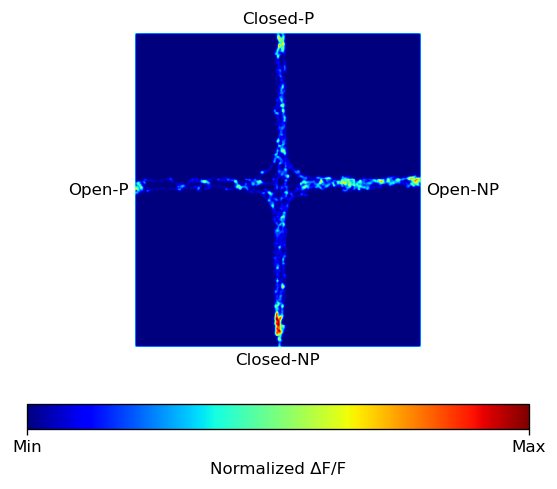

/Users/xiaoqiansun/Desktop/CellReports/results/figures/Fig_4B.png


In [3]:
activity_image = native_spatial_activity_image(
    spatial,
    x_column="X",
    y_column="Y",
    value_column="mean_dff",
    sigma=2,
    normalize=True,
)

fig, ax_map = plt.subplots(figsize=(5, 4), constrained_layout=True)

image_artist = ax_map.imshow(
    activity_image,
    cmap="jet",
    vmin=0,
    vmax=1,
    origin="lower",
    interpolation="nearest",
    aspect="equal",
)
ax_map.set_xticks([])
ax_map.set_yticks([])
for spine in ax_map.spines.values():
    spine.set_visible(False)
ax_map.text(0.50, 1.02, "Closed-P", transform=ax_map.transAxes, ha="center", va="bottom")
ax_map.text(0.50, -0.02, "Closed-NP", transform=ax_map.transAxes, ha="center", va="top")
ax_map.text(-0.02, 0.50, "Open-P", transform=ax_map.transAxes, ha="right", va="center")
ax_map.text(1.02, 0.50, "Open-NP", transform=ax_map.transAxes, ha="left", va="center")
colorbar = fig.colorbar(
    image_artist,
    ax=ax_map,
    orientation="horizontal",
    fraction=0.08,
    pad=0.10,
    ticks=[0, 1],
)
colorbar.ax.set_xticklabels(["Min", "Max"])
colorbar.set_label("Normalized ΔF/F")

png_path = save_figure(fig, OUTPUT_DIR / "Fig_4B.png")
plt.show()
print(png_path)